## Aprendizaje no supervisado: exploración y construcción de perfiles de pozos

En las notebooks anteriores trabajamos con registros mensuales de cada pozo para predecir la producción del mes siguiente. En esta etapa cambiamos la unidad de análisis: cada fila representará un pozo y las columnas resumirán su comportamiento histórico y sus características.

El objetivo de esta notebook es explorar la información disponible y construir una tabla de perfiles por pozo. Esta tabla será utilizada posteriormente para aplicar un modelo de clustering.

Todavía no vamos a aplicar ningún algoritmo de agrupamiento. Primero analizaremos la cantidad de información disponible por pozo, sus variables productivas, sus características generales y la presencia de valores faltantes.

### 1. Importación de librerías

Importamos las librerías que vamos a utilizar para cargar, transformar y explorar los datos. También configuramos la visualización de tablas y gráficos para facilitar la lectura de los resultados.

In [29]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")

sns.set_theme(style="whitegrid")

## 1. Carga de los datos procesados

Para construir los perfiles de los pozos utilizamos el dataset mensual integrado que se generó en las etapas anteriores.

Cada registro representa un pozo en un determinado mes. Posteriormente vamos a agrupar estos registros por `idpozo` para obtener una única fila por pozo.

Utilizamos la información disponible hasta julio de 2026, que corresponde al último período utilizado antes de generar las inferencias para agosto de 2026.

In [30]:
RUTA_PROCESSED = Path("..") / "data" / "processed"

columnas_necesarias = [
    "idpozo",
    "sigla",
    "fecha",
    "prod_pet",
    "prod_gas",
    "prod_agua",
    "tef",
    "meses_desde_inicio",
    "profundidad",
    "cota",
    "cuenca",
    "formacion",
    "tipoestado",
    "tipoextraccion",
    "tipopozo",
    "empresa",
    "provincia",
    "sub_tipo_recurso",
    "tipo_terminacion_ultima",
    "fractura_previa",
    "eventos_fractura_acum",
    "cantidad_fracturas_acum",
    "agua_inyectada_m3_acum",
    "arena_bombeada_tn_acum",
    "longitud_rama_horizontal_m_max",
    "presion_maxima_psi_max",
    "potencia_equipos_fractura_hp_max",
    "meses_desde_ultima_fractura",
]

datos = pd.read_csv(
    RUTA_PROCESSED / "dataset_modelado.csv",
    usecols=columnas_necesarias,
    parse_dates=["fecha"],
    low_memory=False,
)

datos = datos.loc[
    datos["fecha"] <= pd.Timestamp("2026-07-31")
].copy()

datos = datos.sort_values(
    ["idpozo", "fecha"]
).reset_index(drop=True)

print(f"Registros mensuales: {len(datos):,}")
print(f"Pozos identificados: {datos['idpozo'].nunique():,}")
print(
    f"Período analizado: "
    f"{datos['fecha'].min():%Y-%m} a "
    f"{datos['fecha'].max():%Y-%m}"
)

Registros mensuales: 421,046
Pozos identificados: 5,089
Período analizado: 2006-01 a 2026-07


## 2. Cantidad de observaciones por pozo

Antes de construir un único perfil para cada pozo, analizamos cuántos registros mensuales tiene cada uno.

Esta revisión es importante porque no todos los pozos tienen necesariamente la misma cantidad de meses observados. Un pozo con pocos registros puede tener información insuficiente para representar correctamente su comportamiento histórico.

En esta etapa todavía no aplicamos ningún filtro. Primero observamos la distribución de meses disponibles y luego definimos un criterio para conservar los perfiles.

In [31]:
resumen_observaciones = (
    datos.groupby("idpozo", as_index=False)
    .agg(
        sigla=("sigla", "first"),
        meses_observados=("fecha", "nunique"),
        primer_registro=("fecha", "min"),
        ultimo_registro=("fecha", "max"),
    )
)

resumen_observaciones["duracion_calendario_meses"] = (
    (
        resumen_observaciones["ultimo_registro"].dt.year
        - resumen_observaciones["primer_registro"].dt.year
    )
    * 12
    + resumen_observaciones["ultimo_registro"].dt.month
    - resumen_observaciones["primer_registro"].dt.month
    + 1
)

resumen_observaciones.head()

,idpozo,sigla,meses_observados,primer_registro,ultimo_registro,duracion_calendario_meses
0,3640,PPC.Nq.EC-4,246,2006-02-01,2026-07-01,246
1,8043,YPF.Nq.FP.x-2,246,2006-01-01,2026-07-01,247
2,10073,CSJ.RN.LMa.a-3,247,2006-01-01,2026-07-01,247
3,11191,Q.SC.ACI-21,247,2006-01-01,2026-07-01,247
4,11641,TPT.Nq.PS-1001,246,2006-01-01,2026-07-01,247


In [32]:
resumen_observaciones["meses_observados"].describe().round(2)

count   5,089.000
mean       82.740
std        58.320
min         1.000
25%        31.000
50%        81.000
75%       126.000
max       247.000
Name: meses_observados, dtype: float64

### 2.1. Distribución de meses observados

La estadística descriptiva mostró que la cantidad de meses disponibles varía considerablemente entre los pozos. A continuación visualizamos esta distribución para identificar si existen concentraciones de pozos con poca información y si aparecen grupos de pozos con trayectorias más extensas.

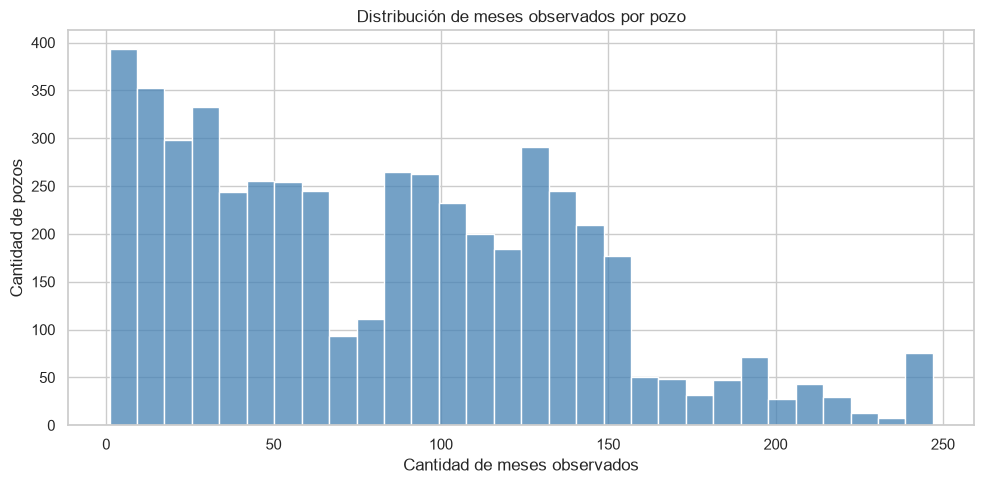

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=resumen_observaciones,
    x="meses_observados",
    bins=30,
    color="steelblue",
    ax=ax
)

ax.set_title("Distribución de meses observados por pozo")
ax.set_xlabel("Cantidad de meses observados")
ax.set_ylabel("Cantidad de pozos")

plt.tight_layout()
plt.show()

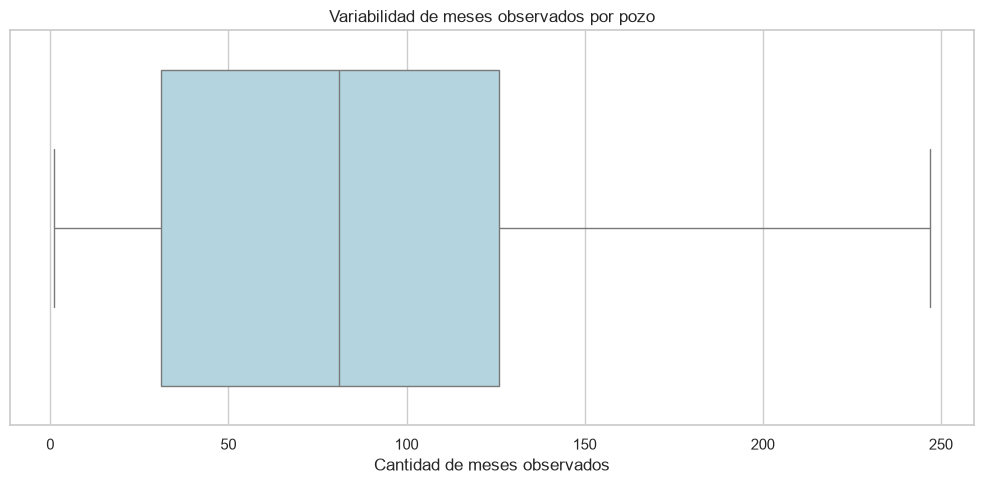

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(
    data=resumen_observaciones,
    x="meses_observados",
    color="lightblue",
    ax=ax
)

ax.set_title("Variabilidad de meses observados por pozo")
ax.set_xlabel("Cantidad de meses observados")

plt.tight_layout()
plt.show()

### 2.2. Comparación de criterios mínimos de observación

La cantidad de meses observados varía considerablemente entre los pozos. Por este motivo, antes de construir los perfiles debemos definir un mínimo de observaciones que permita representar razonablemente el comportamiento histórico de cada pozo.

Comparamos tres alternativas:

- conservar pozos con al menos 3 meses observados;
- conservar pozos con al menos 6 meses observados;
- conservar pozos con al menos 12 meses observados.

La decisión se tomará buscando un equilibrio entre conservar una cantidad suficiente de pozos y evitar perfiles construidos con información demasiado limitada.

In [35]:
minimos_a_evaluar = [3, 6, 12]

tabla_filtros = pd.DataFrame(
    {
        "mínimo_meses": minimos_a_evaluar,
        "pozos_conservados": [
            (
                resumen_observaciones["meses_observados"] >= minimo
            ).sum()
            for minimo in minimos_a_evaluar
        ],
    }
)

tabla_filtros["pozos_eliminados"] = (
    len(resumen_observaciones)
    - tabla_filtros["pozos_conservados"]
)

tabla_filtros["porcentaje_conservado"] = (
    100
    * tabla_filtros["pozos_conservados"]
    / len(resumen_observaciones)
).round(2)

tabla_filtros

,mínimo_meses,pozos_conservados,pozos_eliminados,porcentaje_conservado
0,3,4995,94,98.150
1,6,4839,250,95.090
2,12,4620,469,90.780


### 2.3. Criterio seleccionado

A partir de la comparación realizada, conservamos los pozos que cuentan con al menos seis meses observados.

Este criterio permite excluir los perfiles con información demasiado limitada, manteniendo al mismo tiempo la mayor parte de los pozos disponibles. En total, se conservan 4.839 pozos sobre los 5.089 identificados inicialmente, equivalente al 95,09 % del conjunto.

La elección de seis meses se considera un criterio inicial y podrá revisarse posteriormente mediante un análisis de sensibilidad.

In [36]:
MINIMO_MESES_OBSERVADOS = 6

ids_pozos_validos = resumen_observaciones.loc[
    resumen_observaciones["meses_observados"] >= MINIMO_MESES_OBSERVADOS,
    "idpozo"
]

datos_clustering = datos.loc[
    datos["idpozo"].isin(ids_pozos_validos)
].copy()

datos_clustering = datos_clustering.sort_values(
    ["idpozo", "fecha"]
).reset_index(drop=True)

print(f"Mínimo de meses observado: {MINIMO_MESES_OBSERVADOS}")
print(f"Pozos conservados: {datos_clustering['idpozo'].nunique():,}")
print(f"Registros mensuales conservados: {len(datos_clustering):,}")

Mínimo de meses observado: 6
Pozos conservados: 4,839
Registros mensuales conservados: 420,310


## 3. Construcción de perfiles por pozo

Hasta este punto, cada fila representa un pozo en un mes determinado. Para aplicar clustering necesitamos cambiar la unidad de análisis y construir una única fila por pozo.

Para eso vamos a resumir la información mensual mediante variables que describan:

- el nivel habitual de producción;
- la producción máxima y acumulada;
- la variabilidad;
- la continuidad productiva;
- el comportamiento más reciente.

Primero construiremos las variables relacionadas con la producción de petróleo. Luego incorporaremos las características generales y la información de fracturación.

In [37]:
perfiles_produccion = (
    datos_clustering
    .groupby("idpozo", as_index=False)
    .agg(
        sigla=("sigla", "first"),
        meses_observados=("fecha", "nunique"),
        primer_registro=("fecha", "min"),
        ultimo_registro=("fecha", "max"),
        produccion_media=("prod_pet", "mean"),
        produccion_mediana=("prod_pet", "median"),
        produccion_maxima=("prod_pet", "max"),
        produccion_acumulada=("prod_pet", "sum"),
        desvio_produccion=("prod_pet", "std"),
    )
)

perfiles_produccion.head()

,idpozo,sigla,meses_observados,primer_registro,ultimo_registro,produccion_media,produccion_mediana,produccion_maxima,produccion_acumulada,desvio_produccion
0,3640,PPC.Nq.EC-4,246,2006-02-01,2026-07-01,60.072,51.637,164.532,"14,777.817",34.723
1,8043,YPF.Nq.FP.x-2,246,2006-01-01,2026-07-01,1.967,0.000,82.930,483.900,10.109
2,10073,CSJ.RN.LMa.a-3,247,2006-01-01,2026-07-01,25.759,19.560,328.000,"6,362.390",27.217
3,11191,Q.SC.ACI-21,247,2006-01-01,2026-07-01,5.825,3.820,62.772,"1,438.707",6.868
4,11641,TPT.Nq.PS-1001,246,2006-01-01,2026-07-01,3.453,2.632,13.793,849.321,2.561


### 3.2. Continuidad y producción reciente

Además del nivel productivo general, necesitamos describir si el pozo produjo de manera continua y cómo se comportó en los últimos meses observados.

Para eso calculamos:

- cantidad de meses con producción positiva;
- porcentaje de meses productivos;
- producción del último mes disponible;
- promedio de producción de los últimos tres meses;
- promedio de producción de los últimos seis meses;
- diferencia entre el promedio reciente de tres meses y el promedio de seis meses.

Estas variables permiten distinguir, por ejemplo, entre pozos con producción histórica similar pero con comportamientos recientes diferentes.

In [38]:
datos_clustering["mes_productivo"] = (
    datos_clustering["prod_pet"].fillna(0) > 0
)

continuidad = (
    datos_clustering
    .groupby("idpozo", as_index=False)
    .agg(
        meses_productivos=("mes_productivo", "sum"),
        porcentaje_meses_productivos=("mes_productivo", "mean"),
    )
)

continuidad["porcentaje_meses_productivos"] = (
    100 * continuidad["porcentaje_meses_productivos"]
)

produccion_reciente = (
    datos_clustering
    .sort_values(["idpozo", "fecha"])
    .groupby("idpozo", as_index=False)
    .agg(
        produccion_ultimo_mes=("prod_pet", "last"),
        produccion_media_3m=(
            "prod_pet",
            lambda serie: serie.tail(3).mean()
        ),
        produccion_media_6m=(
            "prod_pet",
            lambda serie: serie.tail(6).mean()
        ),
    )
)

produccion_reciente["cambio_reciente"] = (
    produccion_reciente["produccion_media_3m"]
    - produccion_reciente["produccion_media_6m"]
)

print("Resumen de continuidad productiva")
display(continuidad.head())

print("Resumen de producción reciente")
display(produccion_reciente.head())

Resumen de continuidad productiva


,idpozo,meses_productivos,porcentaje_meses_productivos
0,3640,241,97.967
1,8043,15,6.098
2,10073,242,97.976
3,11191,224,90.688
4,11641,243,98.780


Resumen de producción reciente


,idpozo,produccion_ultimo_mes,produccion_media_3m,produccion_media_6m,cambio_reciente
0,3640,0.001,15.776,21.609,-5.832
1,8043,0.000,0.000,0.000,0.000
2,10073,22.330,22.050,21.800,0.250
3,11191,6.753,2.897,1.889,1.007
4,11641,2.883,2.642,2.655,-0.013


La variable `cambio_reciente` se calcula como la diferencia entre el promedio de los últimos tres meses y el promedio de los últimos seis meses.

- Un valor positivo indica que la producción reciente es mayor que el promedio de los últimos seis meses.
- Un valor negativo indica una disminución reciente.
- Un valor cercano a cero indica estabilidad relativa.

Esta variable se utiliza como una medida descriptiva de la evolución reciente y no como una predicción.

In [39]:
perfiles_produccion = (
    perfiles_produccion
    .merge(continuidad, on="idpozo", how="left")
    .merge(produccion_reciente, on="idpozo", how="left")
)

perfiles_produccion.head()

,idpozo,sigla,meses_observados,primer_registro,ultimo_registro,produccion_media,produccion_mediana,produccion_maxima,produccion_acumulada,desvio_produccion,meses_productivos,porcentaje_meses_productivos,produccion_ultimo_mes,produccion_media_3m,produccion_media_6m,cambio_reciente
0,3640,PPC.Nq.EC-4,246,2006-02-01,2026-07-01,60.072,51.637,164.532,"14,777.817",34.723,241,97.967,0.001,15.776,21.609,-5.832
1,8043,YPF.Nq.FP.x-2,246,2006-01-01,2026-07-01,1.967,0.000,82.930,483.900,10.109,15,6.098,0.000,0.000,0.000,0.000
2,10073,CSJ.RN.LMa.a-3,247,2006-01-01,2026-07-01,25.759,19.560,328.000,"6,362.390",27.217,242,97.976,22.330,22.050,21.800,0.250
3,11191,Q.SC.ACI-21,247,2006-01-01,2026-07-01,5.825,3.820,62.772,"1,438.707",6.868,224,90.688,6.753,2.897,1.889,1.007
4,11641,TPT.Nq.PS-1001,246,2006-01-01,2026-07-01,3.453,2.632,13.793,849.321,2.561,243,98.780,2.883,2.642,2.655,-0.013


In [40]:
print(f"Filas de perfiles: {len(perfiles_produccion):,}")
print(f"Columnas de perfiles: {perfiles_produccion.shape[1]}")
print(f"Pozos únicos: {perfiles_produccion['idpozo'].nunique():,}")

Filas de perfiles: 4,839
Columnas de perfiles: 16
Pozos únicos: 4,839


### 3.3. Características físicas y geológicas

Además del comportamiento productivo, incorporamos variables propias de cada pozo.

Estas variables permiten describir diferencias relacionadas con:

- profundidad;
- ubicación;
- cuenca;
- formación;
- tipo de pozo;
- tipo de extracción;
- empresa operadora;
- estado del pozo.

Para las variables numéricas utilizamos el último valor disponible. Para las variables categóricas utilizamos el último valor registrado, suponiendo que representa la característica vigente del pozo al cierre del período analizado.

Estas variables se conservarán en la tabla de perfiles. Más adelante decidiremos cuáles ingresan directamente al clustering y cuáles se utilizan únicamente para interpretar los grupos.

In [41]:
variables_numericas_pozo = [
    "meses_desde_inicio",
    "profundidad",
    "cota",
    "tef",
]

caracteristicas_numericas = (
    datos_clustering
    .sort_values(["idpozo", "fecha"])
    .groupby("idpozo", as_index=False)
    .agg(
        meses_desde_inicio=("meses_desde_inicio", "last"),
        profundidad=("profundidad", "last"),
        cota=("cota", "last"),
        tef=("tef", "last"),
    )
)

print("Características numéricas por pozo")
display(caracteristicas_numericas.head())

Características numéricas por pozo


,idpozo,meses_desde_inicio,profundidad,cota,tef
0,3640,245,"2,585.000",555.600,0.002
1,8043,246,"3,243.000",463.400,0.000
2,10073,246,"3,850.000",456.300,31.000
3,11191,246,"3,186.000",311.990,26.167
4,11641,246,"3,250.000",593.400,31.000


Las variables numéricas anteriores representan características físicas u operativas del pozo:

- `meses_desde_inicio`: antigüedad relativa del pozo dentro del período observado;
- `profundidad`: profundidad registrada del pozo;
- `cota`: altura o cota asociada al pozo;
- `tef`: indicador operativo disponible en los datos procesados.

Ahora incorporamos las variables categóricas. Estas no se convierten todavía en números porque primero queremos conocer su diversidad y sus valores faltantes.

In [42]:
variables_categoricas_pozo = [
    "tipoestado",
    "tipoextraccion",
    "tipopozo",
    "empresa",
    "cuenca",
    "provincia",
    "formacion",
    "sub_tipo_recurso",
    "tipo_terminacion_ultima",
]

caracteristicas_categoricas = (
    datos_clustering
    .sort_values(["idpozo", "fecha"])
    .groupby("idpozo", as_index=False)[variables_categoricas_pozo]
    .last()
)

caracteristicas_categoricas.head()

,idpozo,tipoestado,tipoextraccion,tipopozo,empresa,cuenca,provincia,formacion,sub_tipo_recurso,tipo_terminacion_ultima
0,3640,Extracción Efectiva,Bombeo Mecánico,Petrolífero,TANGO ENERGY ARGENTINA S.A.,NEUQUINA,Neuquén,VACA MUERTA,SHALE,NaN
1,8043,Parado Transitoriamente,Sin Sistema de Extracción,Gasífero,TECPETROL S.A.,NEUQUINA,Neuquén,VACA MUERTA,SHALE,NaN
2,10073,Extracción Efectiva,Surgencia Natural,Petrolífero,CAPEX S.A.,NEUQUINA,Rio Negro,LAJAS,TIGHT,NaN
3,11191,Extracción Efectiva,Plunger Lift,Gasífero,COMPAÑÍA GENERAL DE COMBUSTIBLES S.A.,AUSTRAL,Santa Cruz,MAGALLANES,TIGHT,Punzado
4,11641,Extracción Efectiva,Surgencia Natural,Gasífero,TECPETROL S.A.,NEUQUINA,Neuquén,LAJAS,TIGHT,NaN


In [43]:
resumen_categoricas = pd.DataFrame(
    {
        "valores_distintos": [
            caracteristicas_categoricas[columna].nunique(dropna=True)
            for columna in variables_categoricas_pozo
        ],
        "valores_faltantes": [
            caracteristicas_categoricas[columna].isna().sum()
            for columna in variables_categoricas_pozo
        ],
    },
    index=variables_categoricas_pozo,
)

print("Resumen de variables categóricas")
display(
    resumen_categoricas
    .sort_values("valores_distintos", ascending=False)
)

Resumen de variables categóricas


,valores_distintos,valores_faltantes
empresa,33,0
formacion,29,0
tipoestado,14,0
tipoextraccion,9,0
tipopozo,6,0
provincia,6,0
tipo_terminacion_ultima,5,1162
cuenca,4,0
sub_tipo_recurso,2,4


### 3.4. Integración de los perfiles por pozo

Ahora unimos las variables productivas, de continuidad, recientes, físicas y categóricas en una única tabla.

La tabla resultante tendrá una fila por pozo. Los identificadores se conservarán para poder reconocer cada registro, pero no se utilizarán como variables de entrada del algoritmo.

En esta etapa todavía no definimos el conjunto final de variables para el clustering. Primero completamos y revisamos la tabla de perfiles. Luego separaremos las variables que ingresarán al modelo de aquellas que se reservarán para interpretar los grupos.

In [44]:
perfiles_pozos = (
    perfiles_produccion
    .merge(caracteristicas_numericas, on="idpozo", how="left")
    .merge(caracteristicas_categoricas, on="idpozo", how="left")
)

print(f"Filas: {len(perfiles_pozos):,}")
print(f"Columnas: {perfiles_pozos.shape[1]}")
print(f"Pozos únicos: {perfiles_pozos['idpozo'].nunique():,}")

display(perfiles_pozos.head())

Filas: 4,839
Columnas: 29
Pozos únicos: 4,839


,idpozo,sigla,meses_observados,primer_registro,ultimo_registro,produccion_media,produccion_mediana,produccion_maxima,produccion_acumulada,desvio_produccion,meses_productivos,porcentaje_meses_productivos,produccion_ultimo_mes,produccion_media_3m,produccion_media_6m,cambio_reciente,meses_desde_inicio,profundidad,cota,tef,tipoestado,tipoextraccion,tipopozo,empresa,cuenca,provincia,formacion,sub_tipo_recurso,tipo_terminacion_ultima
0,3640,PPC.Nq.EC-4,246,2006-02-01,2026-07-01,60.072,51.637,164.532,"14,777.817",34.723,241,97.967,0.001,15.776,21.609,-5.832,245,"2,585.000",555.600,0.002,Extracción Efectiva,Bombeo Mecánico,Petrolífero,TANGO ENERGY ARGENTINA S.A.,NEUQUINA,Neuquén,VACA MUERTA,SHALE,NaN
1,8043,YPF.Nq.FP.x-2,246,2006-01-01,2026-07-01,1.967,0.000,82.930,483.900,10.109,15,6.098,0.000,0.000,0.000,0.000,246,"3,243.000",463.400,0.000,Parado Transitoriamente,Sin Sistema de Extracción,Gasífero,TECPETROL S.A.,NEUQUINA,Neuquén,VACA MUERTA,SHALE,NaN
2,10073,CSJ.RN.LMa.a-3,247,2006-01-01,2026-07-01,25.759,19.560,328.000,"6,362.390",27.217,242,97.976,22.330,22.050,21.800,0.250,246,"3,850.000",456.300,31.000,Extracción Efectiva,Surgencia Natural,Petrolífero,CAPEX S.A.,NEUQUINA,Rio Negro,LAJAS,TIGHT,NaN
3,11191,Q.SC.ACI-21,247,2006-01-01,2026-07-01,5.825,3.820,62.772,"1,438.707",6.868,224,90.688,6.753,2.897,1.889,1.007,246,"3,186.000",311.990,26.167,Extracción Efectiva,Plunger Lift,Gasífero,COMPAÑÍA GENERAL DE COMBUSTIBLES S.A.,AUSTRAL,Santa Cruz,MAGALLANES,TIGHT,Punzado
4,11641,TPT.Nq.PS-1001,246,2006-01-01,2026-07-01,3.453,2.632,13.793,849.321,2.561,243,98.780,2.883,2.642,2.655,-0.013,246,"3,250.000",593.400,31.000,Extracción Efectiva,Surgencia Natural,Gasífero,TECPETROL S.A.,NEUQUINA,Neuquén,LAJAS,TIGHT,NaN


## 4. Revisión de valores faltantes

Antes de aplicar el clustering revisamos la cantidad de valores faltantes en cada variable.

Esta revisión es importante porque los algoritmos de agrupamiento no pueden calcular correctamente las distancias si existen valores ausentes en las variables utilizadas.

También nos permite diferenciar entre:

- variables con pocos valores faltantes, que podrían imputarse;
- variables con muchos faltantes, que podrían excluirse del modelo;
- variables donde la ausencia de información tiene un significado propio.

In [45]:
resumen_faltantes = pd.DataFrame(
    {
        "valores_faltantes": perfiles_pozos.isna().sum(),
        "porcentaje_faltantes": (
            100 * perfiles_pozos.isna().mean()
        ).round(2),
    }
)

resumen_faltantes = (
    resumen_faltantes
    .loc[resumen_faltantes["valores_faltantes"] > 0]
    .sort_values("porcentaje_faltantes", ascending=False)
)

display(resumen_faltantes)

,valores_faltantes,porcentaje_faltantes
tipo_terminacion_ultima,1162,24.010
profundidad,139,2.870
sub_tipo_recurso,4,0.080


### 4.1. Revisión de duplicados

Como la unidad de análisis es el pozo, cada `idpozo` debería aparecer una sola vez en la tabla de perfiles. Verificamos nuevamente que no existan identificadores duplicados después de integrar las distintas tablas.

In [46]:
duplicados_idpozo = perfiles_pozos["idpozo"].duplicated().sum()

print(f"Identificadores duplicados: {duplicados_idpozo:,}")
print(f"Filas totales: {len(perfiles_pozos):,}")
print(f"Pozos únicos: {perfiles_pozos['idpozo'].nunique():,}")

Identificadores duplicados: 0
Filas totales: 4,839
Pozos únicos: 4,839


### 4.2. Decisiones sobre los valores faltantes

La variable `tipo_terminacion_ultima` presenta una proporción elevada de valores faltantes. Por este motivo, no la incorporaremos en la primera versión del clustering. La conservaremos en la tabla para utilizarla posteriormente en la interpretación de los grupos.

La variable `profundidad` tiene un porcentaje reducido de faltantes, por lo que se completará con la mediana de los pozos disponibles.

La variable `sub_tipo_recurso` presenta solamente cuatro valores faltantes. Se completará con la categoría más frecuente.

Estas decisiones se aplican únicamente a la preparación del clustering y quedan documentadas para poder revisarlas posteriormente.

In [47]:
perfiles_pozos["profundidad"] = (
    perfiles_pozos["profundidad"]
    .fillna(perfiles_pozos["profundidad"].median())
)

moda_sub_tipo_recurso = (
    perfiles_pozos["sub_tipo_recurso"]
    .mode(dropna=True)
    .iloc[0]
)

perfiles_pozos["sub_tipo_recurso"] = (
    perfiles_pozos["sub_tipo_recurso"]
    .fillna(moda_sub_tipo_recurso)
)

print(
    f"Mediana utilizada para profundidad: "
    f"{perfiles_pozos['profundidad'].median():,.2f}"
)
print(
    f"Categoría utilizada para sub_tipo_recurso: "
    f"{moda_sub_tipo_recurso}"
)

Mediana utilizada para profundidad: 4,368.50
Categoría utilizada para sub_tipo_recurso: SHALE


In [48]:
faltantes_restantes = (
    perfiles_pozos.isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    faltantes_restantes[
        faltantes_restantes > 0
    ].to_frame("valores_faltantes")
)

,valores_faltantes
tipo_terminacion_ultima,1162


## 5. Selección inicial de variables

No todas las columnas de la tabla de perfiles deben ingresar al algoritmo.

Excluimos:

- `idpozo` y `sigla`, porque son identificadores;
- `primer_registro` y `ultimo_registro`, porque son fechas;
- variables categóricas con muchos valores distintos, que se reservarán inicialmente para interpretar los grupos;
- `tipo_terminacion_ultima`, debido a su cantidad de valores faltantes;
- cualquier objetivo o predicción proveniente de los modelos supervisados.

La primera versión utilizará variables numéricas que describen el nivel productivo, la continuidad, el comportamiento reciente y algunas características físicas del pozo.

In [49]:
variables_clustering_iniciales = [
    "meses_observados",
    "produccion_media",
    "produccion_mediana",
    "produccion_maxima",
    "produccion_acumulada",
    "desvio_produccion",
    "meses_productivos",
    "porcentaje_meses_productivos",
    "produccion_ultimo_mes",
    "produccion_media_3m",
    "produccion_media_6m",
    "cambio_reciente",
    "meses_desde_inicio",
    "profundidad",
    "cota",
    "tef",
]

X_clustering_inicial = perfiles_pozos[
    variables_clustering_iniciales
].copy()

print(f"Perfiles: {X_clustering_inicial.shape[0]:,}")
print(f"Variables seleccionadas: {X_clustering_inicial.shape[1]}")

display(
    pd.DataFrame(
        {
            "variable": variables_clustering_iniciales,
            "tipo": X_clustering_inicial.dtypes.astype(str).values,
            "faltantes": X_clustering_inicial.isna().sum().values,
        }
    )
)

Perfiles: 4,839
Variables seleccionadas: 16


,variable,tipo,faltantes
0,meses_observados,int64,0
1,produccion_media,float64,0
2,produccion_mediana,float64,0
3,produccion_maxima,float64,0
4,produccion_acumulada,float64,0
5,desvio_produccion,float64,0
6,meses_productivos,int64,0
7,porcentaje_meses_productivos,float64,0
8,produccion_ultimo_mes,float64,0
9,produccion_media_3m,float64,0


### 5.1. Descripción de las variables seleccionadas

Las variables seleccionadas resumen diferentes aspectos del comportamiento y de las características de cada pozo.

La tabla final utilizada para el clustering contiene una fila por pozo y no incluye identificadores, fechas ni variables objetivo de los modelos supervisados.

In [50]:
diccionario_clustering = pd.DataFrame(
    {
        "variable": variables_clustering_iniciales,
        "descripción": [
            "Cantidad de registros mensuales disponibles para el pozo.",
            "Producción promedio mensual de petróleo.",
            "Valor central de la producción mensual, menos sensible a valores extremos.",
            "Mayor producción mensual registrada.",
            "Producción total acumulada durante el período analizado.",
            "Desviación estándar de la producción mensual.",
            "Cantidad de meses con producción de petróleo mayor que cero.",
            "Porcentaje de meses en los que el pozo tuvo producción positiva.",
            "Producción registrada en el último mes disponible.",
            "Producción promedio de los últimos tres meses observados.",
            "Producción promedio de los últimos seis meses observados.",
            "Diferencia entre la producción media de los últimos tres y seis meses.",
            "Cantidad de meses transcurridos desde el inicio registrado del pozo.",
            "Profundidad registrada del pozo.",
            "Cota o altura asociada a la ubicación del pozo.",
            "Indicador operativo TEF disponible en los datos procesados.",
        ],
        "tipo": X_clustering_inicial.dtypes.astype(str).values,
        "uso": [
            "Describe la cantidad de historia disponible.",
            "Describe el nivel productivo habitual.",
            "Complementa la media reduciendo el efecto de valores extremos.",
            "Describe el máximo nivel productivo alcanzado.",
            "Describe el volumen producido en todo el período.",
            "Describe la variabilidad productiva.",
            "Describe la continuidad de la producción.",
            "Permite comparar la regularidad productiva entre pozos.",
            "Describe el estado productivo más reciente.",
            "Resume el comportamiento reciente.",
            "Resume una ventana reciente más amplia.",
            "Indica aumento o disminución reciente.",
            "Describe la antigüedad relativa del pozo.",
            "Describe una característica física del pozo.",
            "Describe la ubicación vertical del pozo.",
            "Describe una característica operativa disponible.",
        ],
    }
)

display(diccionario_clustering)

,variable,descripción,tipo,uso
0,meses_observados,Cantidad de registros mensuales disponibles pa...,int64,Describe la cantidad de historia disponible.
1,produccion_media,Producción promedio mensual de petróleo.,float64,Describe el nivel productivo habitual.
2,produccion_mediana,"Valor central de la producción mensual, menos ...",float64,Complementa la media reduciendo el efecto de v...
3,produccion_maxima,Mayor producción mensual registrada.,float64,Describe el máximo nivel productivo alcanzado.
4,produccion_acumulada,Producción total acumulada durante el período ...,float64,Describe el volumen producido en todo el período.
5,desvio_produccion,Desviación estándar de la producción mensual.,float64,Describe la variabilidad productiva.
6,meses_productivos,Cantidad de meses con producción de petróleo m...,int64,Describe la continuidad de la producción.
7,porcentaje_meses_productivos,Porcentaje de meses en los que el pozo tuvo pr...,float64,Permite comparar la regularidad productiva ent...
8,produccion_ultimo_mes,Producción registrada en el último mes disponi...,float64,Describe el estado productivo más reciente.
9,produccion_media_3m,Producción promedio de los últimos tres meses ...,float64,Resume el comportamiento reciente.


Las variables seleccionadas combinan información histórica, productiva, temporal y física. De esta manera, el clustering no se basará únicamente en cuánto produce cada pozo, sino también en su continuidad, variabilidad, evolución reciente y características generales.

Los identificadores `idpozo` y `sigla` se conservarán para reconocer los resultados, pero no ingresarán al algoritmo. Las variables categóricas se reservarán inicialmente para interpretar los grupos una vez obtenidos.

## 6. Revisión de escalas y distribuciones

Antes de calcular distancias entre los pozos, revisamos la escala y la distribución de las variables seleccionadas.

Las variables productivas pueden presentar valores muy asimétricos y diferencias importantes de magnitud. Por ejemplo, la producción acumulada puede tener valores mucho mayores que un porcentaje o una medida de profundidad.

Esta revisión nos permitirá decidir qué variables requieren una transformación logarítmica y luego una estandarización.

In [51]:
display(
    X_clustering_inicial.describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
meses_observados,"4,839.000",86.860,56.840,6.000,36.000,85.000,128.000,247.000
produccion_media,"4,839.000",825.900,"1,244.250",0.000,5.240,93.490,"1,407.310","11,078.780"
produccion_mediana,"4,839.000",699.950,"1,194.240",0.000,0.000,44.680,"1,026.650","9,811.370"
produccion_maxima,"4,839.000","2,413.810","2,938.940",0.000,50.110,863.310,"4,635.080","26,593.260"
produccion_acumulada,"4,839.000","28,666.350","36,905.050",0.000,569.970,"10,545.840","49,534.120","343,442.200"
desvio_produccion,"4,839.000",592.400,784.800,0.000,8.900,140.340,"1,095.510","7,156.570"
meses_productivos,"4,839.000",56.230,49.420,0.000,14.000,43.000,90.000,247.000
porcentaje_meses_productivos,"4,839.000",71.760,37.220,0.000,49.690,92.980,100.000,100.000
produccion_ultimo_mes,"4,839.000",502.410,"1,026.620",0.000,0.000,15.680,580.280,"10,583.300"
produccion_media_3m,"4,839.000",530.530,"1,068.100",0.000,0.000,18.610,613.270,"10,601.250"


## 7. Conclusiones de la exploración y preparación de los perfiles

En esta notebook transformamos los registros mensuales en una tabla con una fila por pozo.

Para cada pozo construimos variables que resumen:

- la cantidad de historia disponible;
- el nivel productivo habitual;
- la producción máxima y acumulada;
- la variabilidad;
- la continuidad productiva;
- el comportamiento reciente;
- algunas características físicas y operativas.

La tabla contiene 4.839 pozos y 16 variables numéricas candidatas para el clustering.

Las variables categóricas, como cuenca, provincia, formación y empresa, no se incorporarán inicialmente al cálculo de distancias. Se conservarán para interpretar los grupos obtenidos posteriormente.

La revisión descriptiva mostró que las variables tienen escalas diferentes y que varias presentan distribuciones asimétricas. Por este motivo, en la siguiente notebook aplicaremos transformaciones logarítmicas cuando corresponda y luego estandarizaremos las variables antes de utilizar DBSCAN.

In [52]:
RUTA_PERFILES = (
    Path("..")
    / "data"
    / "processed"
    / "perfiles_pozos_clustering.csv"
)

perfiles_pozos.to_csv(
    RUTA_PERFILES,
    index=False,
    encoding="utf-8-sig"
)

print(f"Archivo exportado: {RUTA_PERFILES}")
print(f"Filas: {len(perfiles_pozos):,}")
print(f"Columnas: {perfiles_pozos.shape[1]}")

Archivo exportado: ..\data\processed\perfiles_pozos_clustering.csv
Filas: 4,839
Columnas: 29
